# 09 · 欧氏对齐（EA）敏感性分析

检查 session 之间的协方差漂移是否影响历史数据的效果，以及 session-wise EA 能否改善“历史＋当前”。这是一项敏感性分析，使用 Train 验证；规则在运行前写定于 `docs/ea_sensitivity_protocol.md` 与 `configs/ea_sensitivity.json`。

## 方法

EA 位于预处理之后、特征提取之前。对每个 session，在其可用数据的全部保留 flash 上计算参考协方差 R_s（0–800 ms，逐通道去均值，ddof=1，µV²，算术平均），加固定正则 `(1−a)R + a·tr(R)/16·I`，a=0.001；每个试次变换为 R_s^(−1/2)·X。

| Session | 计算 R_s 的数据 |
|---|---|
| S1 | S1 Train 全部 18 个字符（历史） |
| S2 | S2 Train 全部 18 个字符（历史） |
| S3 | 校准池前 k 个字符 |

验证字符与 Test 不参与 R 的计算。k=0 时 S3 没有数据，因此报告 k=3、6、12。窗口均值与通道线性变换可以交换顺序，所以 EA 直接作用在缓存特征上；逐被试用原始 epoch 验证，两者一致（最大误差约 1e−14 µV）。

对照条件：**A** 历史＋当前，不对齐（主设计）；**B** 历史＋当前，session-wise EA；**仅当前**，不对齐；**C** 仅当前，EA。使用全部历史（H=6，36 个字符），SWLDA 设置与主实验相同。A 与仅当前逐被试复现了 notebook 08 的结果。


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/ea_sensitivity.json').exists())
OUT = ROOT / 'outputs/ea_sensitivity_v1'
if not (OUT / 'completion.json').exists():
    raise FileNotFoundError('请先运行 scripts/run_ea_sensitivity.py；本 notebook 不启动拟合。')
completion = json.loads((OUT / 'completion.json').read_text())
display(pd.Series(completion).to_frame('audit'))


,audit
subjects,"[F_03, F_05, F_06, F_07, F_08, F_20, F_21, F_2..."
k_values,"[3, 6, 12]"
fits,120
unaligned_reproduced,60
eegnet_followup_triggered,False
clear_change_k,[]
directions,{'ea_with_history_k3': 'inconsistent_report_pe...
used_test,False
used_s3_validation_for_reference,False
main_results_unchanged,True


## 宏平均差值

`ea_with_history` = B − A；`ea_current_only` = C − 仅当前。区间为按被试配对 bootstrap（10,000 次）的 95% 区间。运行前写定的规则：至少 8/10 名被试与宏平均同号时称“方向一致”，否则按被试报告；某个 k 下 B−A 区间不含 0、方向一致且 |B−A| ≥ 0.01 时，再用 EEGNet 跟进。


In [2]:
macro = pd.read_csv(OUT / 'macro_deltas.csv')
display(macro.round(4))


,k,comparison,subjects,mean_delta,ci_low,ci_high,ci_excludes_zero,n_positive,n_negative,n_zero,direction,mean_auc_aligned,mean_auc_unaligned
0,3,ea_with_history,10,0.0005,-0.0103,0.0128,False,5,5,0,inconsistent_report_per_subject,0.8233,0.8228
1,6,ea_with_history,10,0.0053,-0.0047,0.0187,False,6,4,0,inconsistent_report_per_subject,0.8276,0.8223
2,12,ea_with_history,10,0.0075,-0.0029,0.0228,False,5,5,0,inconsistent_report_per_subject,0.8392,0.8317
3,3,ea_current_only,10,0.0071,-0.0067,0.0223,False,5,5,0,inconsistent_report_per_subject,0.7559,0.7489
4,6,ea_current_only,10,0.0117,-0.0031,0.0291,False,6,4,0,inconsistent_report_per_subject,0.8064,0.7947
5,12,ea_current_only,10,0.0057,-0.0087,0.0222,False,4,6,0,inconsistent_report_per_subject,0.8252,0.8195


## 各条件 AUC

A（不对齐）为蓝色，B（EA）为朱红，C（仅当前＋EA）为灰色虚线；不对齐的仅当前为浅灰点线，标注在线的右侧。纵轴为 0.4–1.0。宏平均中，A 的区间为填充带，B 的区间为细虚线边界。


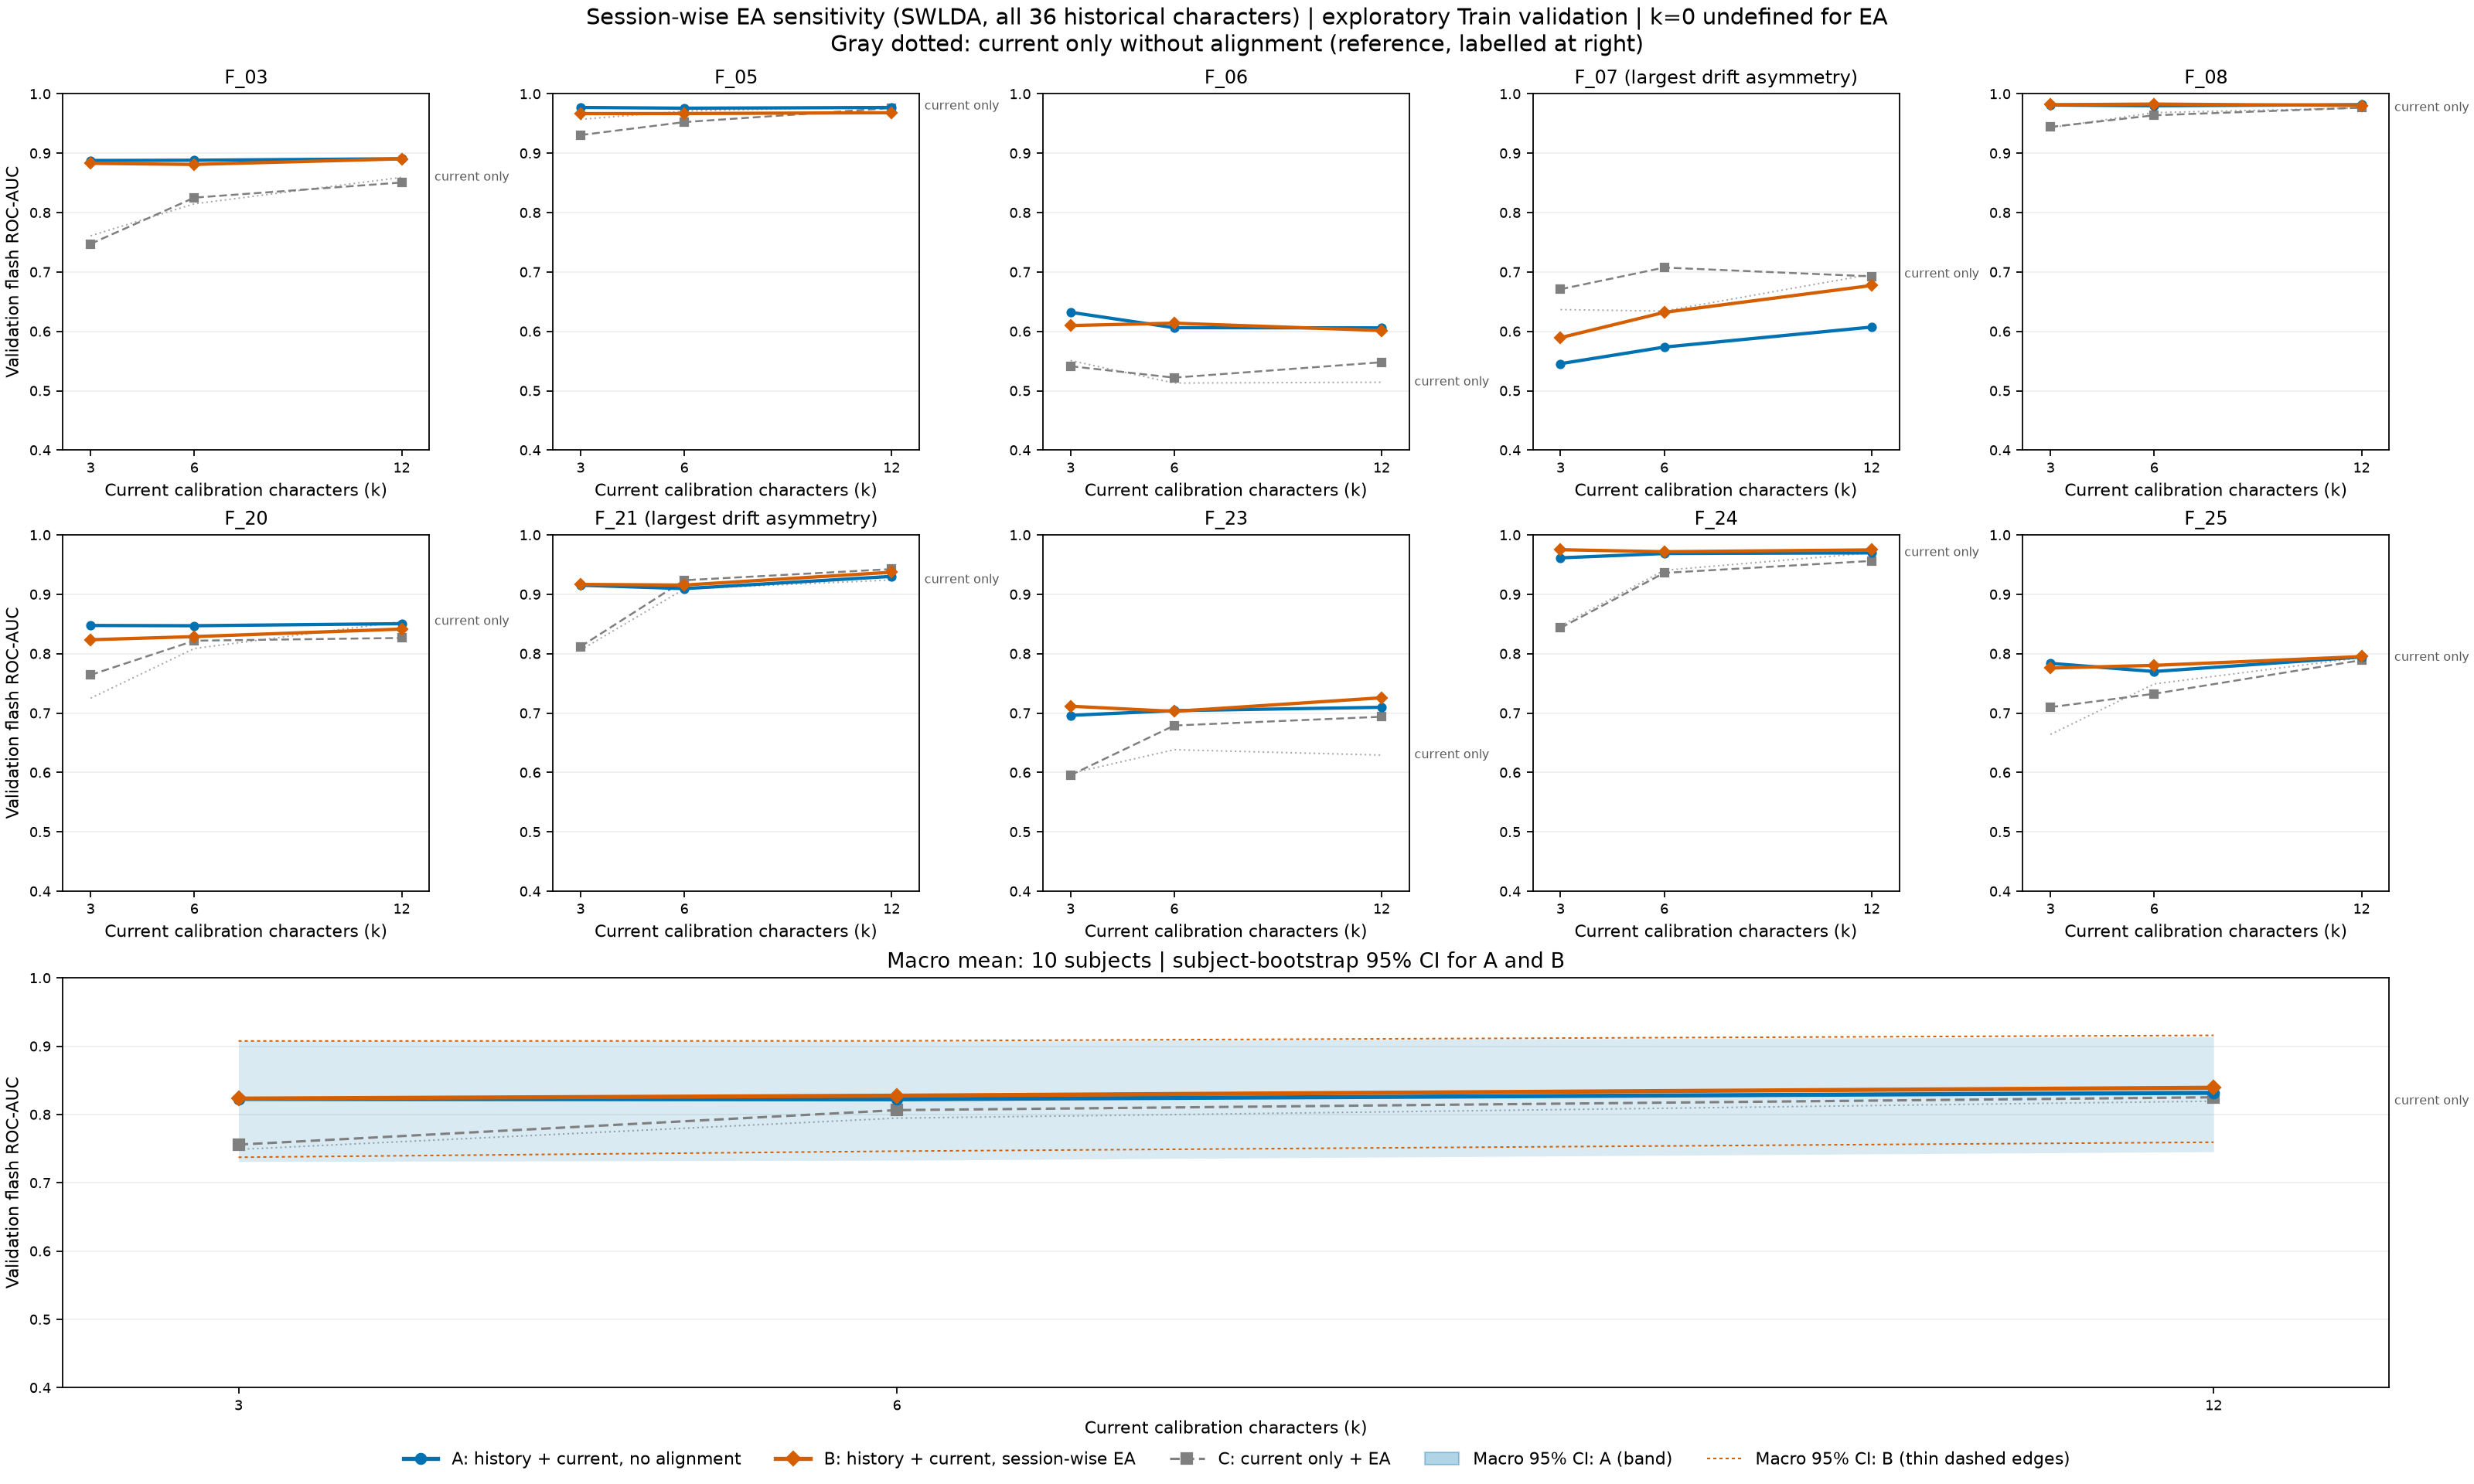

In [3]:
display(Image(filename=str(OUT / 'ea_condition_auc.png')))


## 按被试差值

F_07、F_21 是 session 漂移不对称最明显的两名被试（灰底）。k 的颜色与 notebook 08 相同，由浅到深。


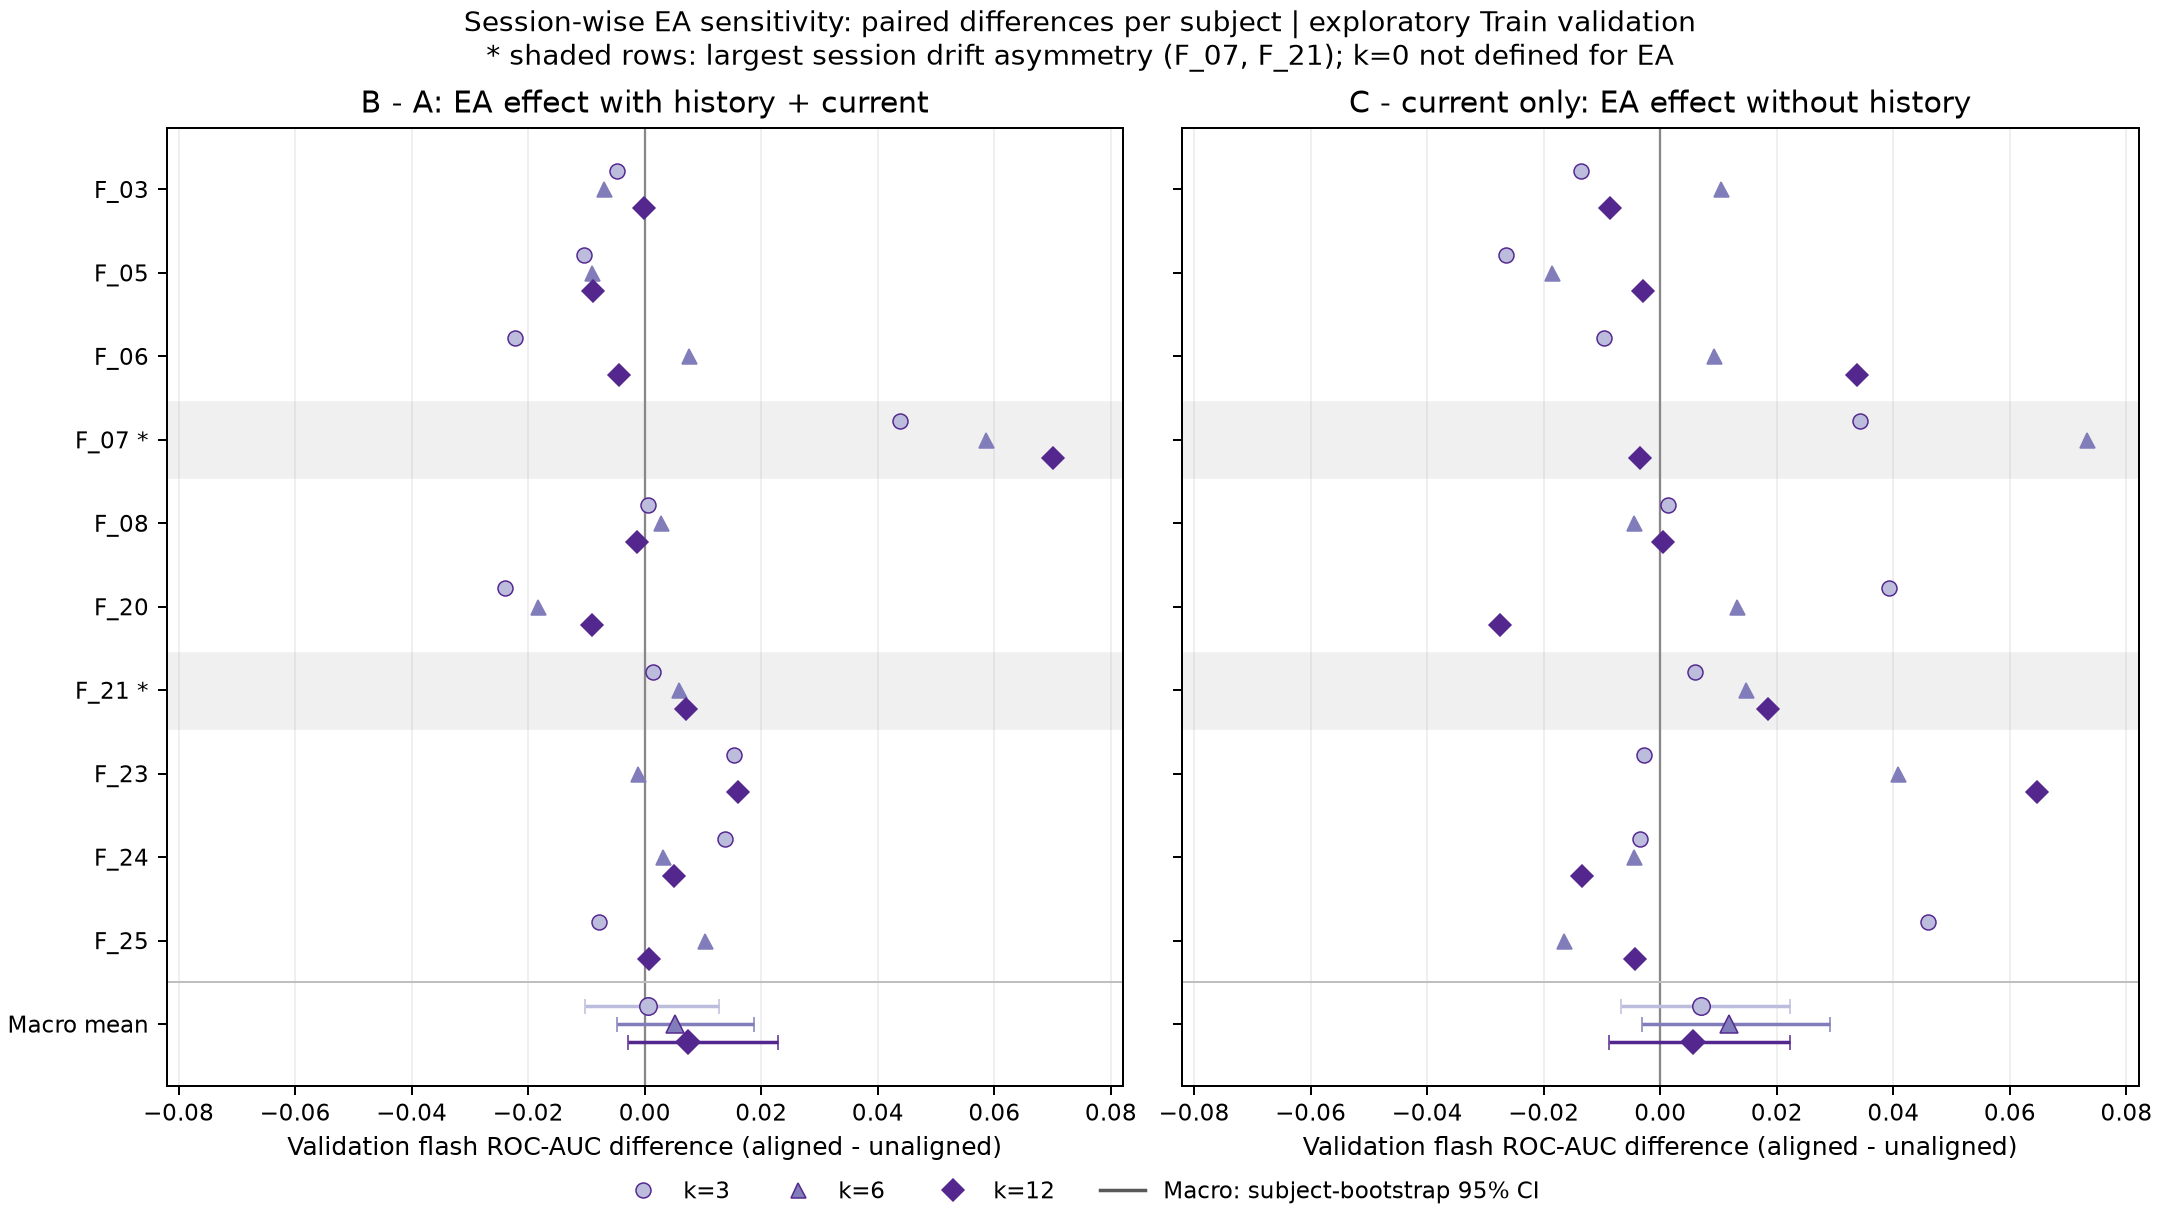

k,B-A k=3,B-A k=6,B-A k=12
subject_id,,,
F_03,-0.005,-0.007,-0.000
F_05,-0.010,-0.009,-0.009
F_06,-0.022,0.008,-0.004
F_07,0.044,0.058,0.070
F_08,0.001,0.003,-0.001
F_20,-0.024,-0.018,-0.009
F_21,0.001,0.006,0.007
F_23,0.015,-0.001,0.016
F_24,0.014,0.003,0.005


k,C-cur k=3,C-cur k=6,C-cur k=12
subject_id,,,
F_03,-0.014,0.010,-0.009
F_05,-0.027,-0.019,-0.003
F_06,-0.010,0.009,0.034
F_07,0.034,0.073,-0.004
F_08,0.001,-0.004,0.000
F_20,0.039,0.013,-0.027
F_21,0.006,0.015,0.018
F_23,-0.003,0.041,0.065
F_24,-0.004,-0.004,-0.014


In [4]:
display(Image(filename=str(OUT / 'ea_subject_deltas.png')))
deltas = pd.read_csv(OUT / 'subject_deltas.csv')
display(deltas.pivot(index='subject_id', columns='k', values='ea_with_history').round(3).add_prefix('B-A k='))
display(deltas.pivot(index='subject_id', columns='k', values='ea_current_only').round(3).add_prefix('C-cur k='))


## 结论

session-wise EA 对 SWLDA“历史＋当前”的宏平均影响很小：B−A 在 k=3、6、12 分别为 +0.001、+0.005、+0.007 AUC，区间均包含 0，各 k 下 5–6/10 名被试为正，方向不一致，因此按被试报告。漂移最大的 F_07 改善明显（+0.04 至 +0.07）。主设计保持不变，EEGNet 跟进条件未满足。

仅当前的 EA（C − 仅当前）方向同样不一致。F_07 的 B−A 随 k 增大而增大，而 C − 仅当前在 k=12 时接近 0，说明它的收益主要来自把 S1 的历史数据对齐到 S3。


## 参考协方差的稳定性

`s3k_to_s3_12_normalized` 是 R_S3(k) 与 R_S3(12) 的归一化 log-Euclidean 距离。k=3 时 R 基于 356 个保留 flash（378 个减去保护期排除），距离普遍大于 k=6。`s1_to_s3k`、`s2_to_s3k` 是对齐前的 session 漂移。


In [5]:
display(pd.read_csv(OUT / 'reference_stability.csv').round(3))
display(pd.read_csv(OUT / 'reference_covariances.csv').round(1))


,subject_id,k,s3_reference_flashes,s3k_to_s3_12_normalized,s1_to_s3k_normalized,s2_to_s3k_normalized
0,F_03,3,356,0.220,0.858,0.881
1,F_03,6,734,0.160,0.849,0.882
2,F_03,12,1468,0.000,0.833,0.861
3,F_05,3,356,0.204,0.816,0.701
4,F_05,6,734,0.143,0.809,0.671
5,F_05,12,1464,0.000,0.779,0.639
6,F_06,3,356,0.247,1.106,0.781
7,F_06,6,734,0.082,1.096,0.715
8,F_06,12,1468,0.000,1.085,0.677
9,F_07,3,356,0.205,1.288,0.521


,subject_id,session_id,k,reference_flashes,reference_characters,min_eigenvalue_uv2,condition_number
0,F_03,SE001,NaN,2202,18,0.4,1376.7
1,F_03,SE002,NaN,2202,18,0.5,1062.9
2,F_03,SE003,3.0,356,3,0.3,1995.1
3,F_03,SE003,6.0,734,6,0.3,1901.2
4,F_03,SE003,12.0,1468,12,0.4,1664.3
5,F_05,SE001,NaN,2198,18,0.9,1278.1
6,F_05,SE002,NaN,2202,18,4.1,480.0
7,F_05,SE003,3.0,356,3,2.3,476.3
8,F_05,SE003,6.0,734,6,2.4,492.1
9,F_05,SE003,12.0,1464,12,2.4,534.3


## 说明

- EA 是线性变换，SWLDA 随后在合并的训练集上逐特征 z-score。z-score 作用于整个训练集，EA 则在合并前逐 session 统一尺度并混合通道，所以 B−A 反映的是两者的组合效应。
- 本分析检验 session-wise EA 一种变体。
- 字符准确率见 `condition_results.csv`。

复现：`python scripts/run_ea_sensitivity.py`；重画图：`python scripts/plot_ea_sensitivity.py`；重建报告：`python scripts/build_ea_sensitivity_notebook.py`。
